# Portfolio 5 — AquaSense+ distributed and cloud database: run and test

This builds a **separate 4-server PostgreSQL lab** in user folder (`~/aquasense_cluster`), copied from your normal PostgreSQL. PostgreSQL is only read from; it is never stopped or crashed.

| Server | Port | Role |
|---|---|---|
| lab primary | 5440 | full copy of your database; system of record and shard coordinator |
| replica1 | 5441 | streaming replica (read-only) |
| shard1 | 5442 | sensor readings for half the farms |
| shard2 | 5443 | sensor readings for the other half |


## 1. Imports and connection

In [1]:
import os, sys, platform, getpass, importlib, re
import pandas as pd
from IPython.display import Image

if platform.system() == "Windows":
    os.environ["PATH"] += r";C:\Program Files\PostgreSQL\16\bin"
os.environ["PGUSER"] = "postgres"
os.environ["PGPASSWORD"] = getpass.getpass("PostgreSQL password: ")
os.environ["PGHOST"] = "localhost"
os.environ["PGPORT"] = "5432"

sys.path.insert(0, os.getcwd())
import cluster_lab as lab
importlib.reload(lab)
print("Files here:", sorted(os.listdir()))
print("Lab folder:", lab.LAB)

PostgreSQL password:  ········


Files here: ['.ipynb_checkpoints', 'README.md', '__pycache__', 'cloud_architecture.dot', 'cloud_architecture.png', 'cluster_lab.py', 'portfolio5_run.ipynb']
Lab folder: C:\Users\user\aquasense_cluster


## 2. Build the cluster (first time 3–15 minutes; later runs just start it)
Copies your server with `pg_basebackup`, makes a streaming replica of the copy, and initialises two empty shard servers. Saved to `evidence/cluster_setup_output.txt`.

In [2]:
lab.setup()


SETUP  4-node PostgreSQL lab
  binaries: C:\Program Files\PostgreSQL\16\bin
  lab folder: C:\Users\user\aquasense_cluster
  source server: localhost:5432
  aquasense database: 267 MB; free disk: 16.1 GB

1. Replication role on your PostgreSQL (the only change made to it)
  role 'replicator' ready (random password stored in the lab folder, not in Git)

2. Lab primary (port 5440): pg_basebackup copy of your server
  copied in 13.3 s
  started; physical replication slot 'replica1_slot' created

3. replica1 (port 5441): pg_basebackup -R -S replica1_slot from the lab primary
  copied in 11.3 s (-R wrote standby.signal + primary_conninfo)

4. Two empty shard servers (ports 5442, 5443)
  shard1 initialised and started
  shard2 initialised and started

Cluster ready
  primary   port 5440: read-write
  replica1  port 5441: standby (read-only)
  shard1    port 5442: read-write
  shard2    port 5443: read-write

[saved to evidence/cluster_setup_output.txt]


## 3. Part A — Replication (about 30 seconds)
- **R1** replication status on both sides
- **R2** replication lag: how long until a new row is visible on the replica
- **R3** the replica refuses writes
- **R4** a heavy report runs on the replica instead of the primary
- **R5** asynchronous vs synchronous commit latency
- **R6** synchronous replication with the replica **down**: writes block (`SyncRep`) — the CAP trade-off in practice

Saved to `evidence/replication_demo_output.txt`.

In [3]:
lab.replication_demo()


R1  REPLICATION STATUS
On the PRIMARY (pg_stat_replication):
  application_name | client_addr | state | sync_state | sent_lsn | replay_lsn | bytes_behind | replay_lag
  replica1 | ::1 | streaming | async | 0/1D028850 | 0/1D028850 | 0 | 0:00:00.026256

On the REPLICA (pg_stat_wal_receiver):
  status | slot_name | sender_port | latest_end_lsn | in_recovery
  streaming | replica1_slot | 5440 | 0/1D028850 | True

Replication slot (keeps WAL until the replica has it, even if it disconnects):
  slot_name | slot_type | active | restart_lsn
  replica1_slot | physical | True | 0/1D028850

R2  REPLICATION LAG - insert on primary, poll replica until visible (30 trials, async mode)
  visible on replica after: median 0.65 ms, max 13.35 ms, min 0.41 ms
  -> eventual consistency window: a read from the replica right after a save can briefly miss it.

R3  THE REPLICA IS READ-ONLY
  SQLSTATE 25006: ERROR:  cannot execute INSERT in a read-only transaction

R4  READ SCALING - cooperative revenue report 

## 4. Part B — Sharding by `hash(farm_id)` (1–3 minutes)
Creates a partitioned table whose two partitions live on the two shard servers (`postgres_fdw`), routes about 1 million readings to them, then shows distribution, skew, single-shard pruning, cross-shard aggregation, write routing and a shard failure.

Saved to `evidence/sharding_setup_output.txt` and `evidence/sharding_demo_output.txt`.

In [4]:
lab.sharding_setup()


S0  SHARDING SETUP - hash(farm_id) over 2 shard servers via postgres_fdw
  shard1: table 'readings' + index created
  shard2: table 'readings' + index created
  coordinator (lab primary): foreign servers, user mappings, hash-partitioned table aqua.wqr_dist
  routed 1,033,624 readings to the shards in 19.3 s

[saved to evidence/sharding_setup_output.txt]


In [5]:
lab.sharding_demo()


S1  DATA DISTRIBUTION - counted directly on each shard server
shard1 (port 5442):
  readings | farms | size
  581403 | 103 | 77 MB
shard2 (port 5443):
  readings | farms | size
  452221 | 77 | 60 MB
Does any farm exist on both shards? (must be 0 - all of a farm's data is co-located)
  farms_on_both
  0

S2  WHY HASH AND NOT REGION? - skew if we had sharded South vs North
  region_shard | farms | pct_of_readings
  North shard | 43 | 23.5
  South shard | 137 | 76.5

  hash_partition | farms | pct_of_readings
  aqua.wqr_dist_p0 | 103 | 56.2
  aqua.wqr_dist_p1 | 77 | 43.8

S3  SINGLE-SHARD QUERY - farm 64's pond dashboard: partition pruning sends it to ONE server
Limit (actual time=30.533..30.538 rows=12 loops=1)
  Output: wqr_dist.unit_id, wqr_dist.recorded_at, wqr_dist.dissolved_oxygen_mgl
  ->  Foreign Scan on aqua.wqr_dist_p0 wqr_dist (actual time=30.525..30.528 rows=12 loops=1)
        Output: wqr_dist.unit_id, wqr_dist.recorded_at, wqr_dist.dissolved_oxygen_mgl
        Remote SQL: S

## 5. Part C — Failover (about 20 seconds)
Crashes the **lab** primary, keeps reading from the replica, promotes the replica, measures RTO and RPO, then rebuilds the lab.

Saved to `evidence/failover_demo_output.txt`.

In [6]:
lab.failover_demo()


F1  BEFORE: roles, timelines and the last farm record written
  primary   port 5440 in_recovery=False timeline=1
  replica1  port 5441 in_recovery=True timeline=1
  'last write before crash' written with id=633

F2  CRASH: lab primary killed with an immediate shutdown (no clean checkpoint)
  primary down at t=0
  connect to primary -> connection to server at "localhost" (::1), port 5440 failed: timeout expired
  replica still serves READS during the outage:
  farms | last_record
  180 | last write before crash

F3  FAILOVER: promote replica1 to primary
  pg_promote() returned True
  in_recovery=False
  new timeline=2
  write accepted on new primary, id=661
  RTO (crash -> promotion complete): 4707 ms;  crash -> first successful write: 6237 ms
  (manual, scripted promotion; real RTO also includes failure detection, e.g. Patroni's ~30 s leader TTL)
  RPO: row 633 ('last write before crash') present on the new primary -> True  => 0 rows lost

F4  SPLIT-BRAIN RISK
  If the old primary sim

## 6. Part D — Proposed cloud deployment

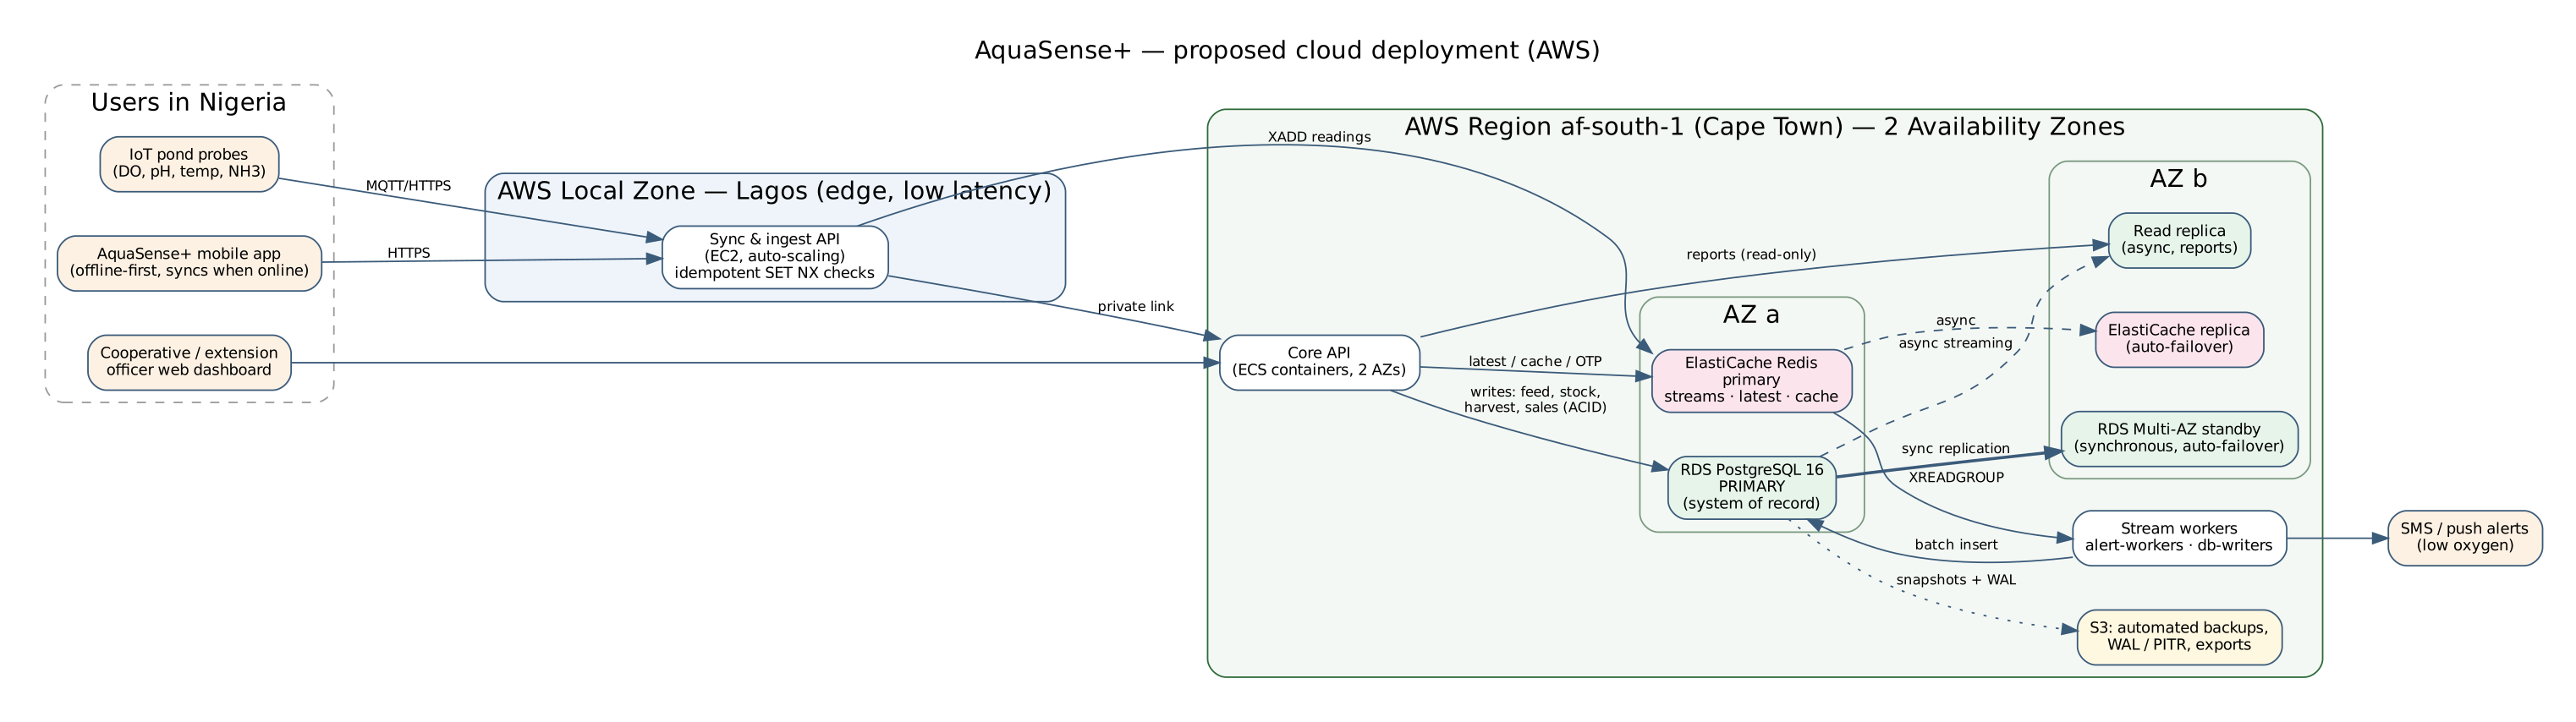

In [7]:
Image("cloud_architecture.png")

## 7. Numbers to copy into the README
Send the saved notebook back to get the README updated.

In [8]:
ev = lambda f: open(os.path.join("evidence", f), encoding="utf-8").read()
rep, shd, fo = ev("replication_demo_output.txt"), ev("sharding_demo_output.txt"), ev("failover_demo_output.txt")
f = lambda pat, src: (re.search(pat, src).group(1) if re.search(pat, src) else "?")
pd.DataFrame([
    {"Item": "R2 replication lag median / max (ms)", "Value": f(r"median ([0-9.]+) ms, max", rep) + " / " + f(r"max ([0-9.]+) ms", rep)},
    {"Item": "R4 report on replica (ms)", "Value": f(r"\(([0-9.]+) ms on the replica", rep)},
    {"Item": "R5 async commit median (ms)", "Value": f(r"asynchronous\s+: median ([0-9.]+)", rep)},
    {"Item": "R5 sync remote_apply median (ms)", "Value": f(r"remote_apply : median ([0-9.]+)", rep)},
    {"Item": "R6 blocked INSERT committed after (s)", "Value": f(r"committed ([0-9.]+) s after", rep)},
    {"Item": "S3 single-shard query (ms)", "Value": f(r"Execution Time: ([0-9.]+) ms", shd)},
    {"Item": "S4 pushdown OFF / ON / single server (ms)", "Value": " / ".join(f(p, shd) for p in (r"pushdown OFF[^:]*:\s+([0-9.]+) ms", r"pushdown ON[^:]*:\s+([0-9.]+) ms", r"single-server table\s*:\s+([0-9.]+) ms"))},
    {"Item": "F3 RTO crash -> promotion (ms)", "Value": f(r"promotion complete\): ([0-9]+) ms", fo)},
    {"Item": "F3 crash -> first write (ms)", "Value": f(r"first successful write: ([0-9]+) ms", fo)},
    {"Item": "F3 RPO", "Value": f(r"=> (.+)", fo)},
])

,Item,Value
0,R2 replication lag median / max (ms),0.65 / 13.35
1,R4 report on replica (ms),58.5
2,R5 async commit median (ms),0.367
3,R5 sync remote_apply median (ms),0.759
4,R6 blocked INSERT committed after (s),5.0
5,S3 single-shard query (ms),31.308
6,S4 pushdown OFF / ON / single server (ms),1406.9 / 374.9 / 509.5
7,F3 RTO crash -> promotion (ms),4707
8,F3 crash -> first write (ms),6237
9,F3 RPO,0 rows lost


## 8. Stop the lab when you are done
Frees memory. To use it again later, rerun cells 1 and 2 (it starts in seconds). To remove it completely, delete the `aquasense_cluster` folder in your user folder after stopping.

In [9]:
lab.stop_all()

All four lab servers stopped (your normal PostgreSQL is untouched).
